# Exploratory analysis: M5 store CA_1, 20 selected products
Goal: understand the data and justify modeling choices (weekly seasonality, intermittent demand, events). Products were selected from the 365 days before the final 28-day holdout, never from the test period (see `data/demo/selection.json`).

In [1]:
import pandas as pd, numpy as np, matplotlib.pyplot as plt
from pathlib import Path
P = next(p for p in [Path("data/demo"), Path("../data/demo")] if p.exists())
df = pd.read_parquet(P / "prepared_sales.parquet")
df["date"] = pd.to_datetime(df["date"])
print(df.shape, df.date.min().date(), "to", df.date.max().date(), "|", df.product_id.nunique(), "products")
df.head()

Matplotlib is building the font cache; this may take a moment.


(38820, 12) 2011-01-29 to 2016-05-22 | 20 products


,product_id,department_id,category_id,store_id,units_sold,date,wday,month,year,event_name_1,event_type_1,snap_CA
0,FOODS_1_041,FOODS_1,FOODS,CA_1,2,2011-01-29,1,1,2011,NaN,NaN,0
1,FOODS_1_041,FOODS_1,FOODS,CA_1,0,2011-01-30,2,1,2011,NaN,NaN,0
2,FOODS_1_041,FOODS_1,FOODS,CA_1,0,2011-01-31,3,1,2011,NaN,NaN,0
3,FOODS_1_041,FOODS_1,FOODS,CA_1,1,2011-02-01,4,2,2011,NaN,NaN,1
4,FOODS_1_041,FOODS_1,FOODS,CA_1,0,2011-02-02,5,2,2011,NaN,NaN,1


## 1. Data quality checks

In [2]:
print("duplicate product-date rows:", df.duplicated(["product_id", "date"]).sum())
print("missing units_sold:", df.units_sold.isna().sum(), "| negative values:", (df.units_sold < 0).sum())
full = pd.date_range(df.date.min(), df.date.max())
print("calendar days missing from data:", len(full.difference(pd.DatetimeIndex(df.date.unique()))))
print("share of product-days with zero sales: %.1f%%" % ((df.units_sold == 0).mean() * 100))

duplicate product-date rows: 0
missing units_sold: 0 | negative values: 0
calendar days missing from data: 0
share of product-days with zero sales: 43.0%


Zero-sales rows are kept as genuine observations. No rows were excluded. Low sales may reflect low demand or unavailable stock; this dataset has no stock records, so the two cannot be separated.

## 2. Sales over time and 7-day rolling average

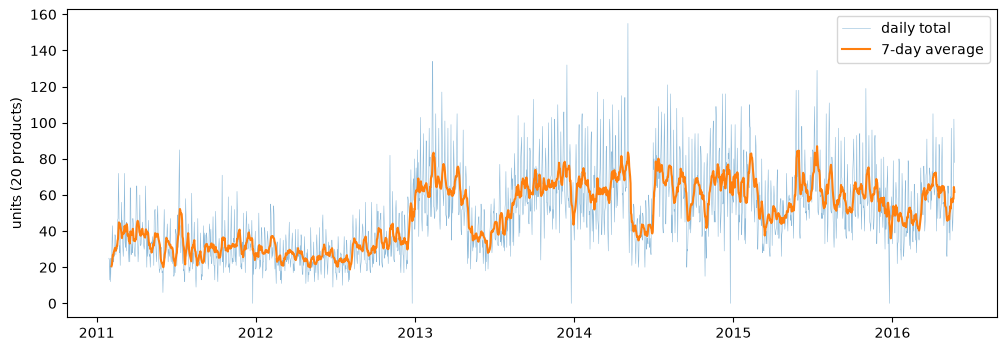

In [3]:
tot = df.groupby("date").units_sold.sum()
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(tot.index, tot.values, lw=0.4, alpha=0.5, label="daily total")
ax.plot(tot.index, tot.rolling(7).mean(), lw=1.5, label="7-day average")
ax.set_ylabel("units (20 products)"); ax.legend(); plt.show()

## 3. Weekly seasonality

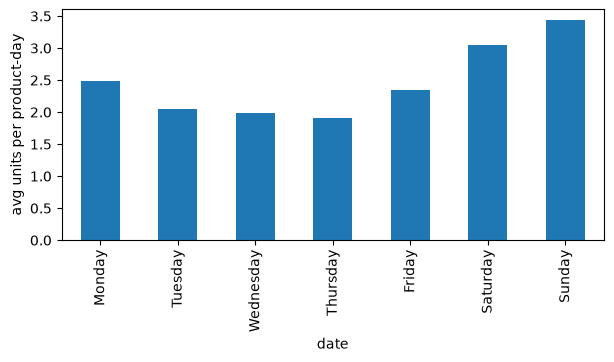

In [4]:
order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
wd = df.groupby(df.date.dt.day_name()).units_sold.mean().reindex(order)
wd.plot.bar(figsize=(7, 3), ylabel="avg units per product-day"); plt.show()

## 4. Demand level and intermittency by product

,mean_units,std,zero_pct
product_id,,,
HOUSEHOLD_1_227,0.47,1.15,80.5
FOODS_2_035,0.52,1.07,75.2
FOODS_3_821,0.52,0.96,69.9
FOODS_3_707,0.71,1.62,72.3
HOUSEHOLD_1_142,0.74,1.06,57.5
HOBBIES_1_394,0.78,1.25,62.2
FOODS_1_041,0.94,1.36,55.2
HOBBIES_1_228,0.96,1.10,43.4
HOUSEHOLD_2_437,1.03,1.24,43.6


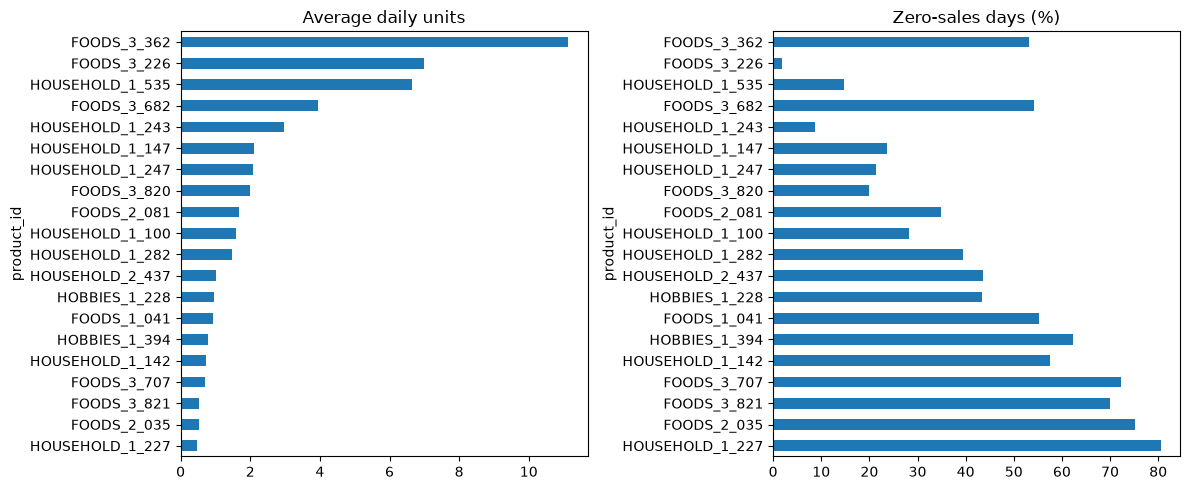

In [5]:
g = df.groupby("product_id").units_sold
summary = pd.DataFrame({"mean_units": g.mean().round(2), "std": g.std().round(2), "zero_pct": (g.apply(lambda s: (s == 0).mean()) * 100).round(1)}).sort_values("mean_units")
display(summary)
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
summary["mean_units"].plot.barh(ax=axes[0], title="Average daily units")
summary["zero_pct"].plot.barh(ax=axes[1], title="Zero-sales days (%)")
plt.tight_layout(); plt.show()

High-volume and low-volume products behave differently: low-volume items are intermittent (many zeros), which is why WAPE is high and why a smooth expected-value forecast cannot match individual spikes.

## 5. Events

In [6]:
d = df.groupby("date").agg(units=("units_sold", "sum"), event=("event_name_1", lambda s: s.notna().any()))
print(d.groupby("event").units.mean().round(1).rename({False: "no event", True: "event day"}))
print("\nMost common events:"); print(df.drop_duplicates("date").event_name_1.value_counts().head(8))

event
no event     49.6
event day    46.4
Name: units, dtype: float64

Most common events:
event_name_1
SuperBowl        6
ValentinesDay    6
PresidentsDay    6
LentStart        6
LentWeek2        6
StPatricksDay    6
Purim End        6
Pesach End       6
Name: count, dtype: int64


Event days average slightly fewer total units (46.4) than non-event days (49.6). This raw comparison is confounded by weekday, season and store closures (for example Christmas Day), so it says nothing causal. The model receives a simple event flag known in advance from the calendar.

## 6. Unusual days

In [7]:
print("Lowest total-sales days:"); print(tot.nsmallest(6))
print("\nHighest total-sales days:"); print(tot.nlargest(6))

Lowest total-sales days:
date
2011-12-25    0
2012-12-25    0
2013-12-25    0
2014-12-25    0
2015-12-25    0
2011-06-02    6
Name: units_sold, dtype: int64

Highest total-sales days:
date
2014-05-04    155
2013-02-10    134
2013-12-15    132
2015-07-12    129
2013-02-09    122
2014-08-03    121
Name: units_sold, dtype: int64


The five lowest days are all December 25 (2011 to 2015) with 0 units across every product, consistent with the store being closed. These rows are kept and documented, not removed.